In [ ]:
!pip -q install kagglehub

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub
import os

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [ ]:
path = kagglehub.dataset_download(
    "vishakhdapat/sms-spam-detection-dataset"
)

print("Dataset downloaded to:", path)

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

100%|██████████| 207k/207k [00:00<00:00, 379kB/s]

Extracting files...
Dataset downloaded to: /root/.cache/kagglehub/datasets/vishakhdapat/sms-spam-detection-dataset/versions/1
/root/.cache/kagglehub/datasets/vishakhdapat/sms-spam-detection-dataset/versions/1/spam_sms.csv


In [ ]:
csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, file))

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found. Check the downloaded dataset files."
    )

print("Available CSV files:")
for i, file in enumerate(csv_files):
    print(i, file)

df = pd.read_csv(csv_files[0])

print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst Five Rows:")
display(df.head())

Available CSV files:
0 /root/.cache/kagglehub/datasets/vishakhdapat/sms-spam-detection-dataset/versions/1/spam_sms.csv

Dataset Shape: (5572, 2)

Column Names:
['v1', 'v2']

First Five Rows:


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Missing Values:
v1    0
v2    0
dtype: int64


In [ ]:
def normalize_column_name(name):
    return "".join(
        ch.lower() for ch in str(name) if ch.isalnum()
    )

normalized_columns = {
    normalize_column_name(col): col
    for col in df.columns
}

text_candidates = [
    "message", "sms", "text", "v2", "messagebody"
]

label_candidates = [
    "label", "category", "class", "v1", "type"
]

text_col = next(
    (normalized_columns[c] for c in text_candidates
     if c in normalized_columns),
    None
)

label_col = next(
    (normalized_columns[c] for c in label_candidates
     if c in normalized_columns),
    None
)

if text_col is None or label_col is None:
    raise ValueError(
        "Could not identify the SMS and label columns. "
        "Check df.columns and set text_col and label_col manually."
    )

data = df[[text_col, label_col]].copy()
data.columns = ["message", "label"]

print(data.head())

                                             message label
0  Go until jurong point, crazy.. Available only ...   ham
1                      Ok lar... Joking wif u oni...   ham
2  Free entry in 2 a wkly comp to win FA Cup fina...  spam
3  U dun say so early hor... U c already then say...   ham
4  Nah I don't think he goes to usf, he lives aro...   ham


In [ ]:
print("Before cleaning:", data.shape)

data = data.dropna(subset=["message", "label"])

data["message"] = data["message"].astype(str).str.strip()
data["label"] = data["label"].astype(str).str.strip().str.lower()

data = data[data["message"] != ""]

# Keep only the two expected classes
data = data[data["label"].isin(["ham", "spam"])]

# Remove duplicate messages
data = data.drop_duplicates(subset=["message"]).reset_index(drop=True)

print("After cleaning:", data.shape)
print("\nClass Distribution:")
print(data["label"].value_counts())

Before cleaning: (5572, 2)
After cleaning: (5158, 2)

Class Distribution:
label
ham     4516
spam     642
Name: count, dtype: int64


In [ ]:
data["label"] = data["label"].map({
    "ham": 0,
    "spam": 1
})

print(data.head())

                                             message  label
0  Go until jurong point, crazy.. Available only ...      0
1                      Ok lar... Joking wif u oni...      0
2  Free entry in 2 a wkly comp to win FA Cup fina...      1
3  U dun say so early hor... U c already then say...      0
4  Nah I don't think he goes to usf, he lives aro...      0


In [ ]:
if len(data) < 2000:
    print("Available messages:", len(data))
    print("Using all available valid messages.")
else:
    data = (
        data.groupby("label", group_keys=False)
        .sample(frac=1, random_state=42)
        .groupby("label", group_keys=False)
        .head(1000)
        .sample(frac=1, random_state=42)
        .reset_index(drop=True)
    )

print("Final Dataset Shape:", data.shape)
print("\nFinal Class Distribution:")
print(data["label"].value_counts())

Final Dataset Shape: (1642, 2)

Final Class Distribution:
label
0    1000
1     642
Name: count, dtype: int64


In [ ]:
import re

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

data["clean_message"] = data["message"].apply(preprocess_text)

print(data[["message", "clean_message", "label"]].head(10))

                                             message  \
0                         Well done and ! luv ya all   
1  Orange brings you ringtones from all time Char...   
2  Of course. I guess god's just got me on hold r...   
3  Feel Yourself That You Are Always Happy.. Slow...   
4  Text BANNEDUK to 89555 to see! cost 150p texto...   
5  FREE NOKIA Or Motorola with upto 12mths 1/2pri...   
6  Do you want a New Nokia 3510i Colour Phone Del...   
7  Reply to win å£100 weekly! Where will the 2006...   
8  Dear Voucher holder Have your next meal on us....   
9  HI DARLIN I FINISH AT 3 DO U 1 2 PICK ME UP OR...   

                                       clean_message  label  
0                           well done and luv ya all      0  
1  orange brings you ringtones from all time char...      1  
2  of course i guess god s just got me on hold ri...      0  
3  feel yourself that you are always happy slowly...      0  
4  text banneduk to 89555 to see cost 150p textop...      1  
5  free nok

In [ ]:
X = data["clean_message"].values
y = data["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 1313
Testing Samples: 329


In [ ]:
MAX_WORDS = 5000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("Vocabulary Size:", vocab_size)
print("Training Shape:", X_train_pad.shape)
print("Testing Shape:", X_test_pad.shape)

print("\nSample Numerical Sequence:")
print(X_train_pad[0])

Vocabulary Size: 4293
Training Shape: (1313, 100)
Testing Shape: (329, 100)

Sample Numerical Sequence:
[   7  912   12   63   43 1205  108  433    7   27    5  913  156  633
  496  118 1206 1207  738  738   34 1208  497  496    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]


In [ ]:

MAX_WORDS = 5000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("Vocabulary Size:", vocab_size)
print("Training Shape:", X_train_pad.shape)
print("Testing Shape:", X_test_pad.shape)

print("\nSample Numerical Sequence:")
print(X_train_pad[0])

Vocabulary Size: 4293
Training Shape: (1313, 100)
Testing Shape: (329, 100)

Sample Numerical Sequence:
[   7  912   12   63   43 1205  108  433    7   27    5  913  156  633
  496  118 1206 1207  738  738   34 1208  497  496    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]


In [ ]:
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 0.6571 - loss: 0.6440 - val_accuracy: 0.8631 - val_loss: 0.4903
Epoch 2/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9629 - loss: 0.2258 - val_accuracy: 0.9430 - val_loss: 0.2131
Epoch 3/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9857 - loss: 0.0664 - val_accuracy: 0.9506 - val_loss: 0.1797
Epoch 4/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.9952 - loss: 0.0342 - val_accuracy: 0.9468 - val_loss: 0.2399
Epoch 5/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.9981 - loss: 0.0173 - val_accuracy: 0.9544 - val_loss: 0.1963
Epoch 6/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.9981 - loss: 0.0131 - val_accuracy: 0.9392 - val_loss: 0.1970


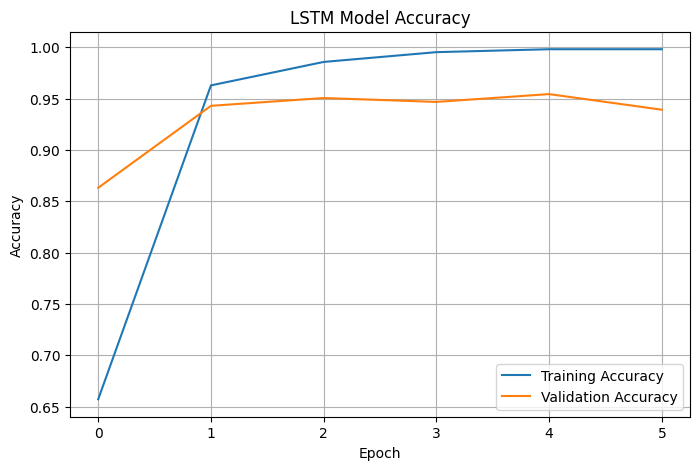

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

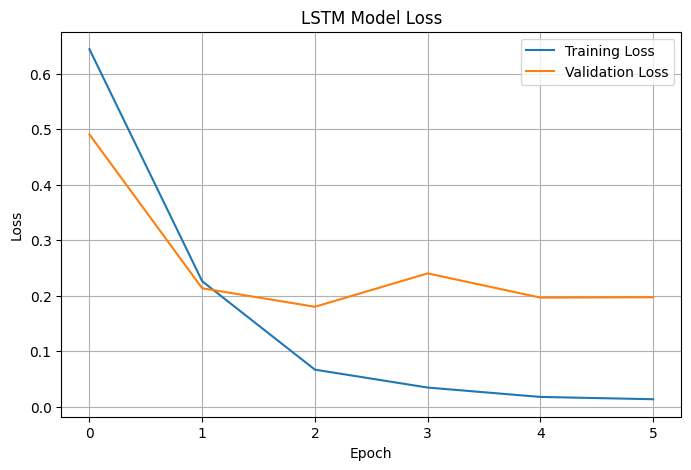

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
y_probability = model.predict(X_test_pad).ravel()

y_pred = (y_probability >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("MODEL EVALUATION RESULTS")
print("-" * 35)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step
MODEL EVALUATION RESULTS
-----------------------------------
Accuracy  : 0.9696
Precision : 0.9612
Recall    : 0.9612
F1-Score  : 0.9612


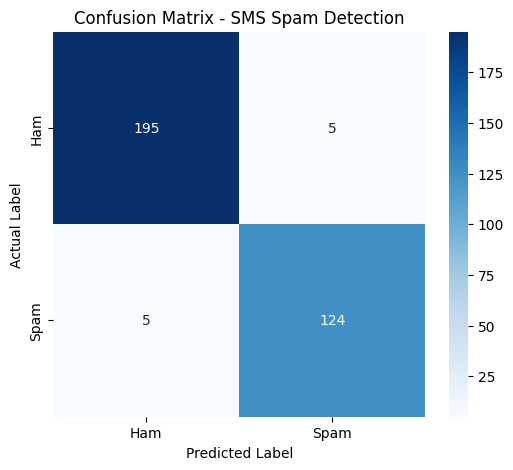


Classification Report:

              precision    recall  f1-score   support

         Ham       0.97      0.97      0.97       200
        Spam       0.96      0.96      0.96       129

    accuracy                           0.97       329
   macro avg       0.97      0.97      0.97       329
weighted avg       0.97      0.97      0.97       329



In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix - SMS Spam Detection")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

In [ ]:
def predict_sms(message):
    cleaned_message = preprocess_text(message)

    sequence = tokenizer.texts_to_sequences(
        [cleaned_message]
    )

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probability = float(model.predict(padded, verbose=0)[0][0])

    if probability >= 0.5:
        prediction = "SPAM"
    else:
        prediction = "HAM (Normal Message)"

    print("Message:", message)
    print("Prediction:", prediction)
    print(f"Spam Probability: {probability:.4f}")
    print("-" * 50)

    return prediction

In [ ]:
test_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hello, are you coming to college tomorrow?",
    "URGENT! Claim your free reward by clicking the link.",
    "Please bring the notes to class today.",
    "You have been selected for a special cash offer."
]

for message in test_messages:
    predict_sms(message)

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Spam Probability: 0.9341
--------------------------------------------------
Message: Hello, are you coming to college tomorrow?
Prediction: HAM (Normal Message)
Spam Probability: 0.0153
--------------------------------------------------
Message: URGENT! Claim your free reward by clicking the link.
Prediction: SPAM
Spam Probability: 0.9292
--------------------------------------------------
Message: Please bring the notes to class today.
Prediction: HAM (Normal Message)
Spam Probability: 0.0503
--------------------------------------------------
Message: You have been selected for a special cash offer.
Prediction: SPAM
Spam Probability: 0.6360
--------------------------------------------------
